In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# from embo import InformationBottleneck
import ndd
import itertools
import utilities as utils

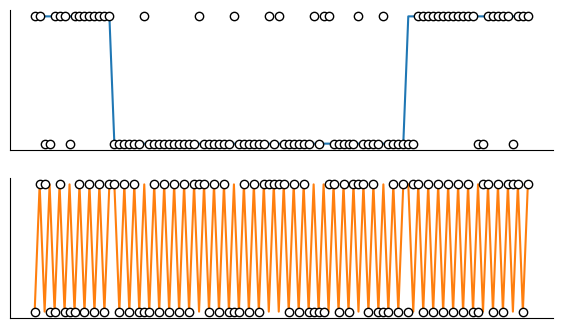

In [2]:
cmap = plt.get_cmap("tab10")

# get hidden markov and markov bead data
mm_df = pd.read_csv('./MM_beads_finaldat_long.csv')
hmm_df = pd.read_csv('./HMM_inst_beads_finaldat_long.csv')
hmm_noinst_df = pd.read_csv('./HMM_noinst_beads_finaldat_long.csv')

# Plot of example trials
hmm_lo = hmm_df.loc[hmm_df.Session == 'Low'].copy()
hmm_hi = hmm_df.loc[hmm_df.Session == 'High'].copy()
mm_lo = mm_df.loc[mm_df.Session == 'Low'].copy()
mm_hi = mm_df.loc[mm_df.Session == 'High'].copy()
hmm_noinst_lo = hmm_noinst_df.loc[hmm_noinst_df.Session == 'Low'].copy()
hmm_noinst_hi = hmm_noinst_df.loc[hmm_noinst_df.Session == 'High'].copy()
et_lo = hmm_lo.iloc[100:200].copy()
et_hi = hmm_hi.iloc[100:200].copy()

plt.figure(1,(7,4))
plt.subplot(2,1,1)
plt.plot(et_lo['Jar'],color=cmap(0))
plt.plot(et_lo['Bead'],'o',mec='black',mfc='white')
plt.xticks([])
plt.yticks([])

plt.subplot(2,1,2)
plt.plot(et_hi['Jar'],color=cmap(1))
plt.plot(et_hi['Bead'],'o',mec='black',mfc='white',label='Bead Color')
plt.xticks([])
plt.yticks([])
sns.despine()

In [3]:
hmm_lo

,Subject,Sequence,Session,Sess_Order,SessTrial,TSCP,TSCP2,Jar,Bead,Resp,Correct_Bead,Correct_Jar,RT,Study,Resp01
500,S1_inst,63,Low,2,1,0.0,0,1.0,1.0,1.0,1,1,1159.670,HMM_inst,0.0
501,S1_inst,63,Low,2,2,1.0,1,1.0,1.0,1.0,1,1,233.050,HMM_inst,0.0
502,S1_inst,63,Low,2,3,2.0,2,1.0,1.0,1.0,1,1,191.770,HMM_inst,0.0
503,S1_inst,63,Low,2,4,3.0,3-4,1.0,1.0,1.0,1,1,72.000,HMM_inst,0.0
504,S1_inst,63,Low,2,5,4.0,3-4,1.0,1.0,1.0,1,1,6.640,HMM_inst,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66495,S87_inst,59,Low,1,496,18.0,8+,1.0,1.0,1.0,1,1,181.215,HMM_inst,0.0
66496,S87_inst,59,Low,1,497,19.0,8+,1.0,1.0,1.0,1,1,386.405,HMM_inst,0.0
66497,S87_inst,59,Low,1,498,20.0,8+,1.0,1.0,2.0,0,0,285.650,HMM_inst,1.0
66498,S87_inst,59,Low,1,499,21.0,8+,1.0,1.0,1.0,1,1,352.940,HMM_inst,0.0


In [4]:
window_size = 7
N_threads = 14
Xset = utils.get_beads_Xset(window_size)
Xset1b = utils.get_beads_Xset(1)

# generative parameters for the bead-prediction experiment
hhmmlo_=0.99 # jar stay probability
hhmmhi_=0.01
hmmlo_=0.32
hmmhi_=0.68
p0hmm_=0.8 # probability of drawing bead type 0 from jar 0
p1hmm_=0.2 # probability of drawing bead type 0 from jar 1
p0mm_=1.0
p1mm_=0.0
P0 = np.array([[0.5, 0.5]]) # prior over jars for computing posterior probabilities over hidden markov process
p_Y = P0.copy()

Hhmmlo = np.ones((2,2)) - np.abs(np.eye(2)*-1 + hhmmlo_) # transition matrix
Hhmmhi = np.ones((2,2)) - np.abs(np.eye(2)*-1 + hhmmhi_) # transition matrix for high jar stay probability
Hmmlo = np.ones((2,2)) - np.abs(np.eye(2)*-1 + hmmlo_) # transition matrix for low jar stay probability
Hmmhi = np.ones((2,2)) - np.abs(np.eye(2)*-1 + hmmhi_) # transition matrix for high jar stay probability
Ehmm = np.vstack((np.array([[1,0]])*p0hmm_ + np.array([[0,1]])*(1-p0hmm_),np.array([[1,0]])*p1hmm_ + np.array([[0,1]])*(1-p1hmm_))) # emission matrix
Emm = np.vstack((np.array([[1,0]])*p0mm_ + np.array([[0,1]])*(1-p0mm_),np.array([[1,0]])*p1mm_ + np.array([[0,1]])*(1-p1mm_))) # emission matrix for memoryless model

p_XgY_hmmlo = utils.P_beads_g_jar(Xset,Ehmm,Hhmmlo)
p_XgY_hmmlo1b = utils.P_beads_g_jar(Xset1b,Ehmm,Hhmmlo)
p_XgY_hmmhi = utils.P_beads_g_jar(Xset,Ehmm,Hhmmhi)
p_XgY_hmmhi1b = utils.P_beads_g_jar(Xset1b,Ehmm,Hhmmhi)

IB_bound_hmmlo = utils.get_IB_bound(p_XgY_hmmlo,p_Y,N_threads=N_threads)
IB_bound_hmmhi = utils.get_IB_bound(p_XgY_hmmhi,p_Y,N_threads=N_threads)
IB_bound_hmmlo1b = utils.get_IB_bound(p_XgY_hmmlo1b,p_Y,N_threads=N_threads)
IB_bound_hmmhi1b = utils.get_IB_bound(p_XgY_hmmhi1b,p_Y,N_threads=N_threads)

p_XgY_mmlo = utils.P_beads_g_jar(Xset,Emm,Hmmlo)
p_XgY_mmlo1b = utils.P_beads_g_jar(Xset1b,Emm,Hmmlo)
p_XgY_mmhi = utils.P_beads_g_jar(Xset,Emm,Hmmhi)
p_XgY_mmhi1b = utils.P_beads_g_jar(Xset1b,Emm,Hmmhi)

IB_bound_mmlo = utils.get_IB_bound(p_XgY_mmlo,p_Y,N_threads=N_threads)
IB_bound_mmhi = utils.get_IB_bound(p_XgY_mmhi,p_Y,N_threads=N_threads)
IB_bound_mmlo1b = utils.get_IB_bound(p_XgY_mmlo1b,p_Y,N_threads=N_threads)
IB_bound_mmhi1b = utils.get_IB_bound(p_XgY_mmhi1b,p_Y,N_threads=N_threads)



/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  return np.sum(p_RgX*p_X*np.log2(p_RgX/p_R))
/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  return np.sum(p_RgX*p_X*np.log2(p_RgX/p_R))
/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  return np.sum(p_RgX*p_X*np.log2(p_RgX/p_R))
/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  return np.sum(p_RgX*p_X*np.log2(p_RgX/p_R))
/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  return np.sum(p_RgX*p_X*np.log2(p_RgX/p_R))
/workspaces/behavioral_data_reanalyses_IB/Filipowicz_beads/utilities.py:129: RuntimeWarning: divide by zero encountered in log2
  

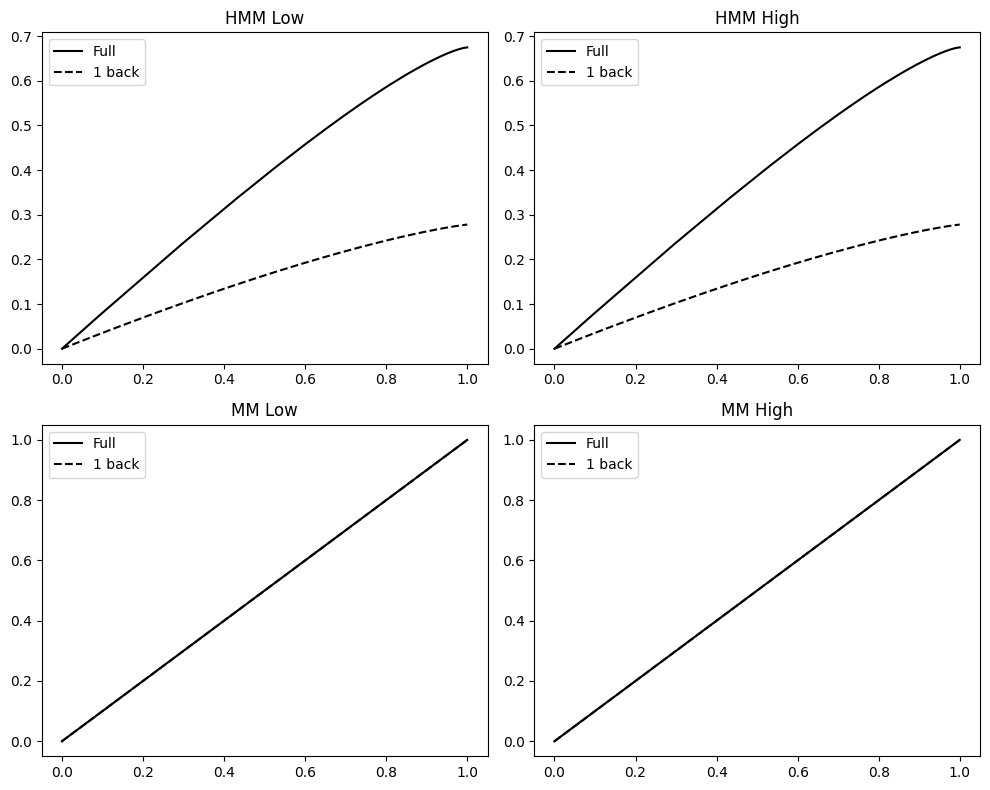

In [5]:
fig,axs = plt.subplots(2,2, figsize=(10,8))

axs[0,0].plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full')
axs[0,0].plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back')
axs[0,0].set_title('HMM Low')
axs[0,0].legend()

axs[0,1].plot(IB_bound_hmmhi['I_XR'],IB_bound_hmmhi['I_RY'],'k',label='Full')
axs[0,1].plot(IB_bound_hmmhi1b['I_XR'],IB_bound_hmmhi1b['I_RY'],'k--',label='1 back')
axs[0,1].set_title('HMM High')
axs[0,1].legend()

axs[1,0].plot(IB_bound_mmlo['I_XR'],IB_bound_mmlo['I_RY'],'k',label='Full')
axs[1,0].plot(IB_bound_mmlo1b['I_XR'],IB_bound_mmlo1b['I_RY'],'k--',label='1 back')
axs[1,0].set_title('MM Low')
axs[1,0].legend()

axs[1,1].plot(IB_bound_mmhi['I_XR'],IB_bound_mmhi['I_RY'],'k',label='Full')
axs[1,1].plot(IB_bound_mmhi1b['I_XR'],IB_bound_mmhi1b['I_RY'],'k--',label='1 back')
axs[1,1].set_title('MM High')
axs[1,1].legend()

plt.tight_layout()

In [6]:
ibdf = pd.DataFrame({
    'subject_id': [],
    'hazard_block': [],
    'hmm_or_mm_exp': [],
    'inst_or_noinst': [],
    'Ixr': [],
    'Iry': [],
    'Iry_CI_lower': [],
    'Iry_CI_upper': []
})

Xcard = 2**window_size
Rcard = 2
Ycard = 2
CI = (2.5, 97.5)
boot_iters = 1000 # number of bootstrap iterations

for ii,sub in enumerate(pd.unique(hmm_lo['Subject'])):

    X_, Y_ = utils.getXY_beads(hmm_lo.loc[hmm_lo['Subject']==sub,"Bead"].to_numpy()-1,hmm_lo.loc[hmm_lo['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(hmm_lo.loc[hmm_lo['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'low', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'hmm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'inst', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

for ii,sub in enumerate(pd.unique(hmm_hi['Subject'])):

    X_, Y_ = utils.getXY_beads(hmm_hi.loc[hmm_hi['Subject']==sub,"Bead"].to_numpy()-1,hmm_hi.loc[hmm_hi['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(hmm_hi.loc[hmm_hi['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'high', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'hmm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'inst', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

for ii,sub in enumerate(pd.unique(mm_lo['Subject'])):

    X_, Y_ = utils.getXY_beads(mm_lo.loc[mm_lo['Subject']==sub,"Bead"].to_numpy()-1,mm_lo.loc[mm_lo['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(mm_lo.loc[mm_lo['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'low', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'mm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'na', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

for ii,sub in enumerate(pd.unique(mm_hi['Subject'])):

    X_, Y_ = utils.getXY_beads(mm_hi.loc[mm_hi['Subject']==sub,"Bead"].to_numpy()-1,mm_hi.loc[mm_hi['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(mm_hi.loc[mm_hi['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'high', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'mm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'na', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

for ii,sub in enumerate(pd.unique(hmm_noinst_lo['Subject'])):

    X_, Y_ = utils.getXY_beads(hmm_noinst_lo.loc[hmm_noinst_lo['Subject']==sub,"Bead"].to_numpy()-1,hmm_noinst_lo.loc[hmm_noinst_lo['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(hmm_noinst_lo.loc[hmm_noinst_lo['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'low', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'hmm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'noinst', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

for ii,sub in enumerate(pd.unique(hmm_noinst_hi['Subject'])):

    X_, Y_ = utils.getXY_beads(hmm_noinst_hi.loc[hmm_noinst_hi['Subject']==sub,"Bead"].to_numpy()-1,hmm_noinst_hi.loc[hmm_noinst_hi['Subject']==sub,"Jar"].to_numpy()-1,window_size,encodeX=True)
    R_ = utils.getR_beads(hmm_noinst_hi.loc[hmm_noinst_hi['Subject']==sub,"Resp"].to_numpy(),window_size)

    Ixr_ = utils.mutual_inf_nsb(X_,R_,[Xcard,Rcard])
    Iry_ = utils.mutual_inf_nsb(R_,Y_,[Rcard,Ycard])

    Iry_CI = utils.get_Iry_CI(R_,Y_,CI,boot_iters,Rcard=Rcard,Ycard=Ycard,seed=234,N_threads=N_threads)

    ibdf = pd.concat([ibdf,pd.DataFrame({
        'subject_id': [sub],
        'hazard_block': 'high', # replace with actual hazard block if available
        'hmm_or_mm_exp': 'hmm', # replace with actual model/experiment info if available
        'inst_or_noinst': 'noinst', # replace with actual inst/noinst info if available
        'Ixr': [Ixr_],
        'Iry': [Iry_],
        'Iry_CI_lower': [Iry_CI[0]],
        'Iry_CI_upper': [Iry_CI[1]]
    })], ignore_index=True)

In [7]:
ibdf['exclude_Ixr'] = ibdf['Ixr'].apply(lambda x: False if x >= 0.05 else True)
ibdf['exclude_Ixr_any'] = np.nan
for ii, sub in enumerate(ibdf['subject_id'].unique()):
    ibdf.loc[ibdf['subject_id'] == sub, 'exclude_Ixr_any'] = ibdf.loc[ibdf['subject_id'] == sub, 'exclude_Ixr'].any()


/tmp/ipykernel_3668/4245876614.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'True' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  ibdf.loc[ibdf['subject_id'] == sub, 'exclude_Ixr_any'] = ibdf.loc[ibdf['subject_id'] == sub, 'exclude_Ixr'].any()


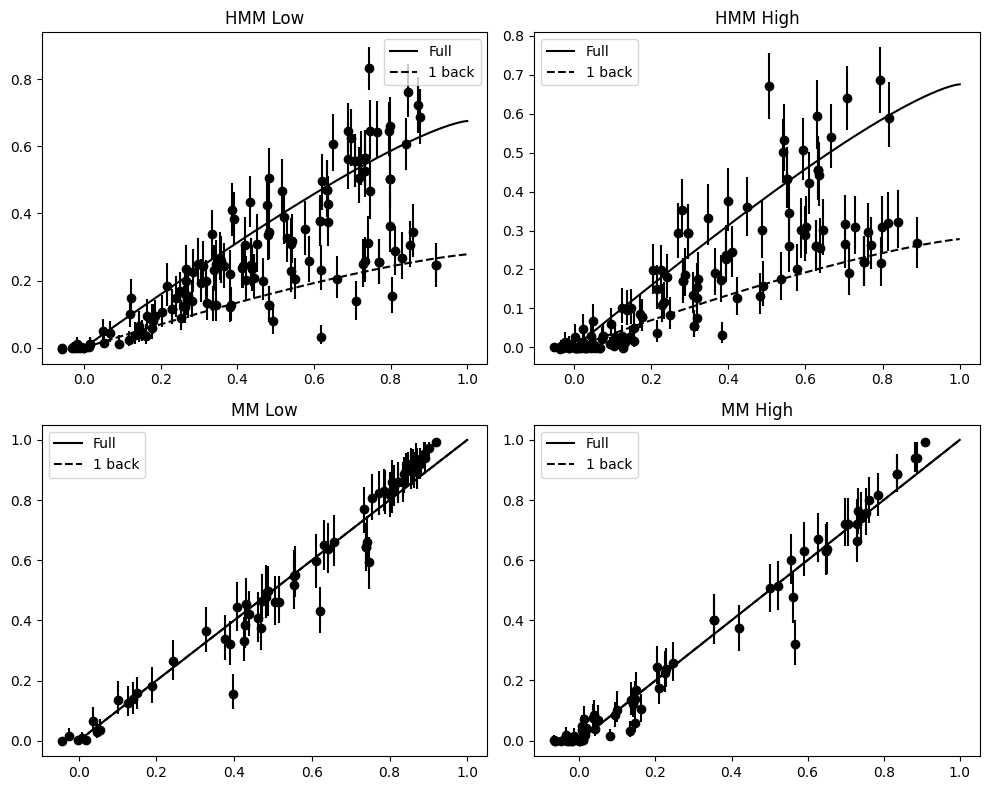

In [8]:
fig,axs = plt.subplots(2,2, figsize=(10,8))

ibconds = (ibdf['hazard_block'] == 'low') & (ibdf['hmm_or_mm_exp'] == 'hmm')
axs[0,0].plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full')
axs[0,0].plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back')
axs[0,0].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[0,0].set_title('HMM Low')
axs[0,0].legend()

ibconds = (ibdf['hazard_block'] == 'high') & (ibdf['hmm_or_mm_exp'] == 'hmm')
axs[0,1].plot(IB_bound_hmmhi['I_XR'],IB_bound_hmmhi['I_RY'],'k',label='Full')
axs[0,1].plot(IB_bound_hmmhi1b['I_XR'],IB_bound_hmmhi1b['I_RY'],'k--',label='1 back')
axs[0,1].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[0,1].set_title('HMM High')
axs[0,1].legend()

ibconds = (ibdf['hazard_block'] == 'low') & (ibdf['hmm_or_mm_exp'] == 'mm')
axs[1,0].plot(IB_bound_mmlo['I_XR'],IB_bound_mmlo['I_RY'],'k',label='Full')
axs[1,0].plot(IB_bound_mmlo1b['I_XR'],IB_bound_mmlo1b['I_RY'],'k--',label='1 back')
axs[1,0].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[1,0].set_title('MM Low')
axs[1,0].legend()

ibconds = (ibdf['hazard_block'] == 'high') & (ibdf['hmm_or_mm_exp'] == 'mm')
axs[1,1].plot(IB_bound_mmhi['I_XR'],IB_bound_mmhi['I_RY'],'k',label='Full')
axs[1,1].plot(IB_bound_mmhi1b['I_XR'],IB_bound_mmhi1b['I_RY'],'k--',label='1 back')
axs[1,1].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[1,1].set_title('MM High')
axs[1,1].legend()

plt.tight_layout()

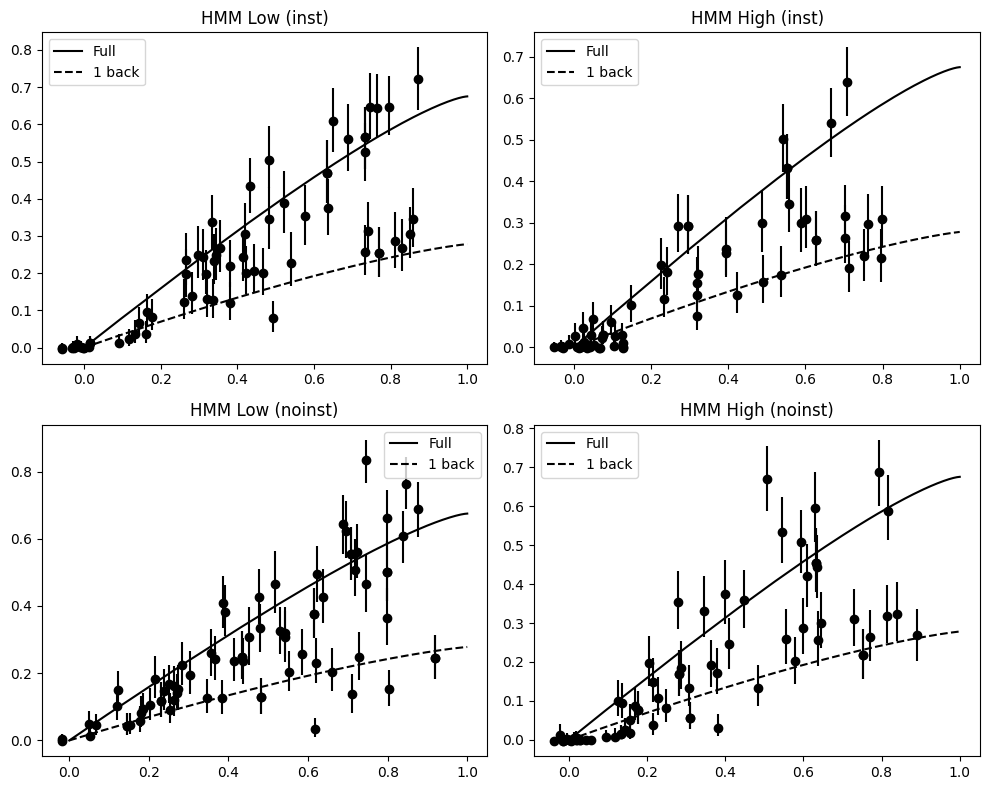

In [9]:
fig,axs = plt.subplots(2,2, figsize=(10,8))

ibconds = (ibdf['hazard_block'] == 'low') & (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst'] == 'inst')
axs[0,0].plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full')
axs[0,0].plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back')
axs[0,0].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[0,0].set_title('HMM Low (inst)')
axs[0,0].legend()

ibconds = (ibdf['hazard_block'] == 'high') & (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst'] == 'inst')
axs[0,1].plot(IB_bound_hmmhi['I_XR'],IB_bound_hmmhi['I_RY'],'k',label='Full')
axs[0,1].plot(IB_bound_hmmhi1b['I_XR'],IB_bound_hmmhi1b['I_RY'],'k--',label='1 back')
axs[0,1].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[0,1].set_title('HMM High (inst)')
axs[0,1].legend()

ibconds = (ibdf['hazard_block'] == 'low') & (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst'] == 'noinst')
axs[1,0].plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full')
axs[1,0].plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back')
axs[1,0].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[1,0].set_title('HMM Low (noinst)')
axs[1,0].legend()

ibconds = (ibdf['hazard_block'] == 'high') & (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst'] == 'noinst')
axs[1,1].plot(IB_bound_hmmhi['I_XR'],IB_bound_hmmhi['I_RY'],'k',label='Full')
axs[1,1].plot(IB_bound_hmmhi1b['I_XR'],IB_bound_hmmhi1b['I_RY'],'k--',label='1 back')
axs[1,1].errorbar(ibdf.loc[ibconds,'Ixr'],ibdf.loc[ibconds,'Iry'],yerr=[ibdf.loc[ibconds,'Iry']-ibdf.loc[ibconds,'Iry_CI_lower'],ibdf.loc[ibconds,'Iry_CI_upper']-ibdf.loc[ibconds,'Iry']],fmt='o',color='black')
axs[1,1].set_title('HMM High (noinst)')
axs[1,1].legend()

plt.tight_layout()

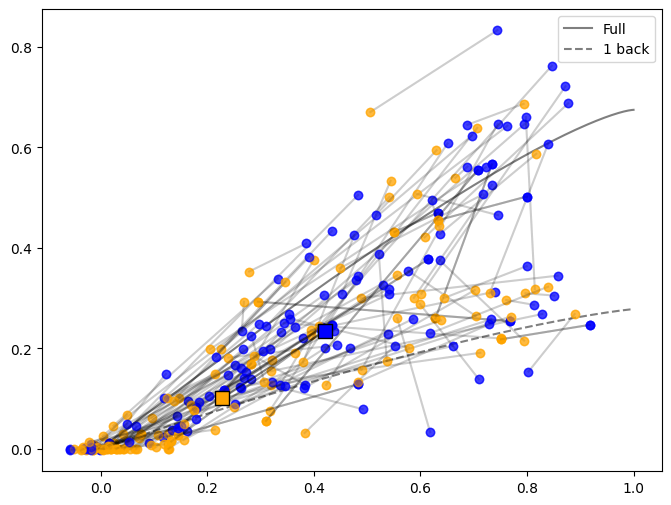

In [10]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm')
median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
ax.legend()

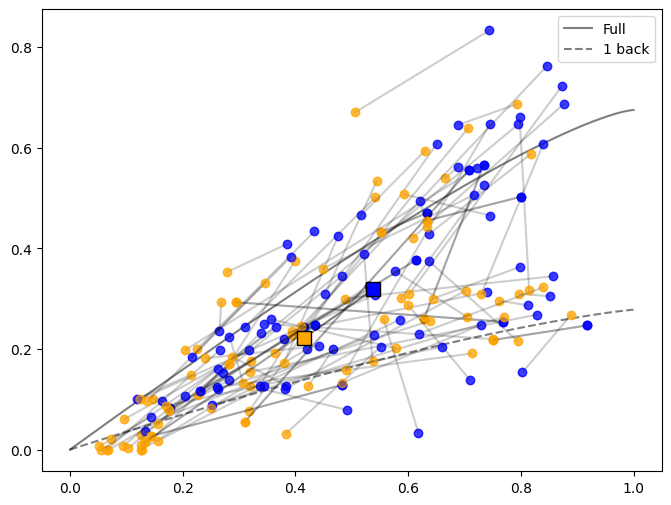

In [11]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm') & (~ibdf['exclude_Ixr_any'])
# median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
# median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
# median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
# median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()
mean_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].mean()
mean_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].mean()
mean_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].mean()
mean_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([mean_hmmlo_Ixr, mean_hmmhi_Ixr], [mean_hmmlo_Iry, mean_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(mean_hmmlo_Ixr, mean_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(mean_hmmhi_Ixr, mean_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
# ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
# ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.vlines([0.05],ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1])
ax.legend()

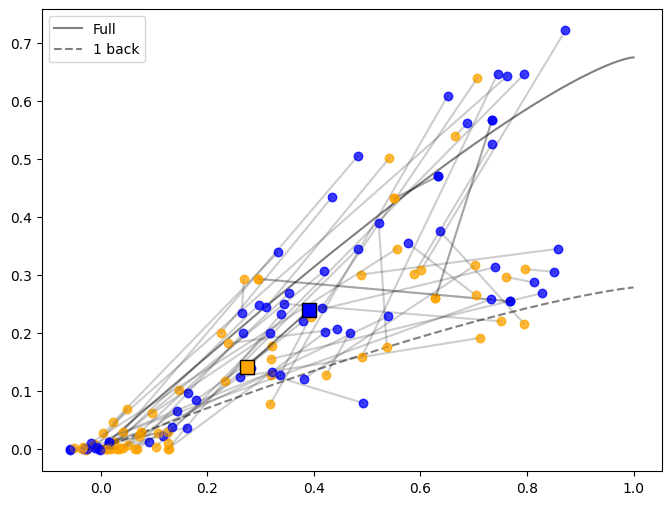

In [13]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst']=='inst')
# median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
# median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
# median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
# median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()
mean_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].mean()
mean_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].mean()
mean_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].mean()
mean_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([mean_hmmlo_Ixr, mean_hmmhi_Ixr], [mean_hmmlo_Iry, mean_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(mean_hmmlo_Ixr, mean_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(mean_hmmhi_Ixr, mean_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
# ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
# ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.vlines([0.05],ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1])
ax.legend()

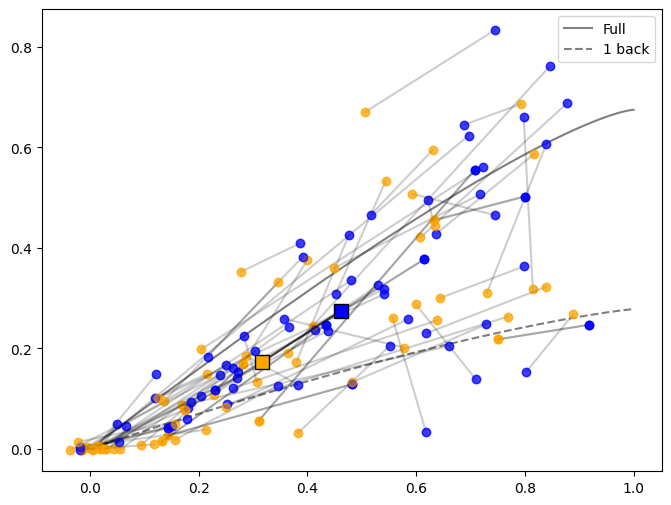

In [14]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst']=='noinst')
# median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
# median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
# median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
# median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()
mean_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].mean()
mean_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].mean()
mean_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].mean()
mean_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([mean_hmmlo_Ixr, mean_hmmhi_Ixr], [mean_hmmlo_Iry, mean_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(mean_hmmlo_Ixr, mean_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(mean_hmmhi_Ixr, mean_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
# ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
# ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.vlines([0.05],ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1])
ax.legend()

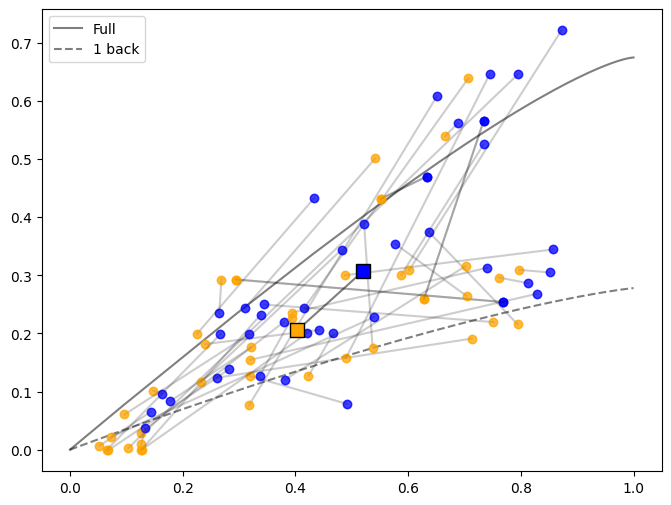

In [15]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst']=='inst') & (~ibdf['exclude_Ixr_any'])
# median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
# median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
# median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
# median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()
mean_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].mean()
mean_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].mean()
mean_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].mean()
mean_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([mean_hmmlo_Ixr, mean_hmmhi_Ixr], [mean_hmmlo_Iry, mean_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(mean_hmmlo_Ixr, mean_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(mean_hmmhi_Ixr, mean_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
# ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
# ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.vlines([0.05],ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1])
ax.legend()

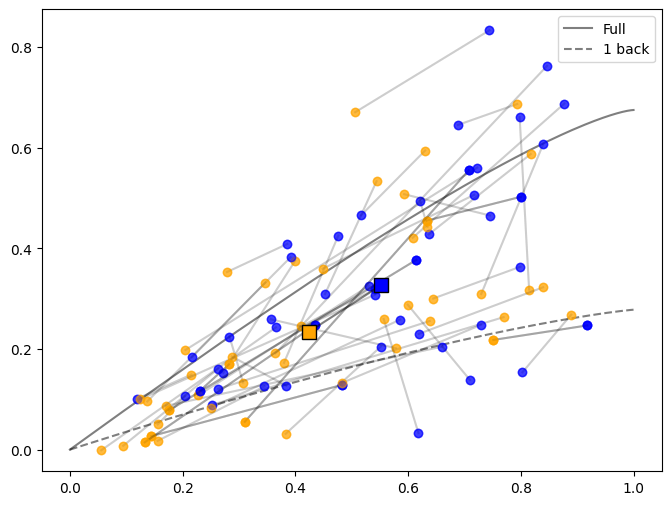

In [16]:
conds = (ibdf['hmm_or_mm_exp'] == 'hmm') & (ibdf['inst_or_noinst']=='noinst') & (~ibdf['exclude_Ixr_any'])
# median_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].median()
# median_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].median()
# median_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].median()
# median_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].median()
mean_hmmlo_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Ixr'].mean()
mean_hmmhi_Ixr = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Ixr'].mean()
mean_hmmlo_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'low'),'Iry'].mean()
mean_hmmhi_Iry = ibdf.loc[conds & (ibdf['hazard_block'] == 'high'),'Iry'].mean()

fig, ax = plt.subplots(figsize=(8,6))

ax.plot(IB_bound_hmmlo['I_XR'],IB_bound_hmmlo['I_RY'],'k',label='Full',alpha=0.5)
ax.plot(IB_bound_hmmlo1b['I_XR'],IB_bound_hmmlo1b['I_RY'],'k--',label='1 back',alpha=0.5)
for ii, sub in enumerate(ibdf.loc[conds,'subject_id']):
    conds1 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'low')
    conds2 = conds & (ibdf['subject_id'] == sub) & (ibdf['hazard_block'] == 'high')
    ax.plot([ibdf.loc[conds1,'Ixr'].values[0], ibdf.loc[conds2,'Ixr'].values[0]], [ibdf.loc[conds1,'Iry'].values[0], ibdf.loc[conds2,'Iry'].values[0]], 'k-', alpha=0.1)
    ax.plot(ibdf.loc[conds1,'Ixr'],ibdf.loc[conds1,'Iry'],'o',color='blue',alpha=0.5)
    ax.plot(ibdf.loc[conds2,'Ixr'],ibdf.loc[conds2,'Iry'],'o',color='orange',alpha=0.5)
ax.plot([mean_hmmlo_Ixr, mean_hmmhi_Ixr], [mean_hmmlo_Iry, mean_hmmhi_Iry], 'k-', alpha=0.5)
ax.plot(mean_hmmlo_Ixr, mean_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
ax.plot(mean_hmmhi_Ixr, mean_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.plot([median_hmmlo_Ixr, median_hmmhi_Ixr], [median_hmmlo_Iry, median_hmmhi_Iry], 'k-', alpha=0.5)
# ax.plot(median_hmmlo_Ixr, median_hmmlo_Iry, 'bs', markersize=10, alpha=1, mec='black')
# ax.plot(median_hmmhi_Ixr, median_hmmhi_Iry, 's', color='orange', markersize=10, alpha=1, mec='black')
# ax.vlines([0.05],ymin=ax.get_ylim()[0], ymax=ax.get_ylim()[1])
ax.legend()